# Baseline CNN: what we tried and what we learned

Can a small convolutional neural network recognise 12 thermal solar-module classes from **40 × 24 grayscale images**?
We first establish a predictor that does not learn, then compare CNN capacity and training choices. Two SmallCNN references survive because higher overall F1 and fewer missed faults favour different configurations.

Read [data exploration](01_data_exploration.ipynb) first. This notebook displays tracked evidence, with optional local image examples. Detailed trials, unsuccessful runs and their original plans remain in the [experiment archive](../archive/README.md).

In [1]:
from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src/pv_fault").is_dir():
    raise RuntimeError("Run from the repository root or notebooks folder.")
sys.path.insert(0, str(ROOT / "src"))
from pv_fault.data import CLASS_NAMES, CLASS_TO_INDEX
from pv_fault.plots import learning_curves, confusion_matrix, image_examples

SEED = 2112
manifest_path = ROOT / "data/splits/infrared_solar_modules_v1.csv"
manifest_sha = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
manifest_summary = json.loads(manifest_path.with_suffix(".json").read_text())
assert manifest_sha == manifest_summary["manifest_sha256"]
manifest = pd.read_csv(manifest_path, dtype=str)
assert manifest.groupby("group_id")["split"].nunique().eq(1).all()
validation_rows = manifest.loc[manifest["split"].eq("val")]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Frozen split checked. This notebook reads recorded results; it does not train or evaluate test images.")

Frozen split checked. This notebook reads recorded results; it does not train or evaluate test images.


## 1. Begin with an understandable model

A convolution learns local image patterns; pooling reduces their spatial size. Our initial SmallCNN has two convolution blocks (16 and 32 channels), ReLU activations and a small classifier. WideCNN tests capacity by widening those blocks to 64 and 128 channels.

| Step | Shape for one image |
|---|---|
| Brightness scaled to 0–1 | `1 × 40 × 24` |
| First convolution and max pooling | `16 × 20 × 12` |
| Second convolution and max pooling | `32 × 10 × 6` |
| Adaptive average pooling | `32 × 4 × 4` |
| Classifier | 12 class scores |

Later SmallCNN candidates add a third convolution and BatchNorm, which normalises intermediate features during fitting. Keep these architecture changes explicit when comparing their results.

In [2]:
from pv_fault.models.baseline import SmallCNN, WideCNN

torch.manual_seed(SEED)
models = {"Initial SmallCNN": SmallCNN(), "Initial WideCNN": WideCNN(),
          "Selected SmallCNN architecture": SmallCNN(batch_norm=True, extra_conv=True)}
print(models["Initial SmallCNN"])
parameter_counts = {name: sum(p.numel() for p in model.parameters()) for name, model in models.items()}
assert parameter_counts["Initial SmallCNN"] == 38412
assert parameter_counts["Initial WideCNN"] == 338316
assert parameter_counts["Selected SmallCNN architecture"] == 47820
display(pd.Series(parameter_counts, name="Parameters").to_frame())

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=512, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=12, bias=True)
  )
)


,Parameters
Initial SmallCNN,38412
Initial WideCNN,338316
Selected SmallCNN architecture,47820


## 2. Establish a baseline that does not learn

Choose the most common class using **training labels only**, then predict it for every validation image. This gives about 50% accuracy while missing every fault.

Use **macro-F1** (equal weight to each class), balanced accuracy and per-class recall alongside accuracy. Also count faults called `No-Anomaly` and normal images incorrectly flagged as faulty; those errors have different practical consequences.

In [3]:
from pv_fault.evaluate import classification_metrics

training_rows = manifest.loc[manifest["split"].eq("train")]
counts = training_rows["label"].value_counts()
majority = max(CLASS_NAMES, key=lambda name: (counts.get(name, 0), -CLASS_TO_INDEX[name]))
truth = [CLASS_TO_INDEX[label] for label in validation_rows["label"]]
majority_metrics = classification_metrics(truth, [CLASS_TO_INDEX[majority]] * len(truth))
display(pd.DataFrame([{"Predictor": f"Always {majority}",
    "Accuracy": majority_metrics["accuracy"], "Macro-F1": majority_metrics["macro_f1"],
    "Missed faults": majority_metrics["faults_called_normal"],
    "Normal false alarms": majority_metrics["normal_called_fault"]}]).set_index("Predictor").round(4))

,Accuracy,Macro-F1,Missed faults,Normal false alarms
Predictor,,,,
Always No-Anomaly,0.5007,0.0556,1492,0


## 3. Follow the useful experimental progression

We increased training time, compared widths and learning rates, then tested scheduling, BatchNorm, depth, activation, optimisers and mild augmentation. Class weights use training counts only; validation selects checkpoints and settings.

The table shows the strongest recorded candidate within each phase. **Rows compare complete configurations:** improvements across phases cannot be attributed to one setting alone. The linked records contain matched controls and all trial outcomes.

In [4]:
extended = json.loads((ROOT / "results/cnn-training-comparison-v1.json").read_text())
ablation = json.loads((ROOT / "results/cnn-scheduler-batchnorm-v1.json").read_text())
search = json.loads((ROOT / "results/cnn-search-45min-v1.json").read_text())
optimisers = json.loads((ROOT / "results/cnn-optimizers-v1.json").read_text())
followup = json.loads((ROOT / "results/smallcnn-20min-v1.json").read_text())
assert all(record["test_evaluated"] is False for record in (search, optimisers, followup))
phases = {"Width, rate and duration": extended, "Scheduler and BatchNorm": ablation,
          "Depth and activation search": search["experiments"],
          "Optimiser follow-up": optimisers["controls"] + optimisers["experiments"],
          "Longer training and augmentation": [followup["control"]] + followup["experiments"]}
progression = []
for phase, runs in phases.items():
    chosen = max(runs, key=lambda run: run["metrics"]["macro_f1"])
    assert chosen["provenance"]["manifest_sha256"] == manifest_sha
    assert chosen["summary"]["test_evaluated"] is False
    assert chosen["metrics"]["count"] == len(validation_rows)
    metrics = chosen["metrics"]
    progression.append({"Phase": phase, "Run": chosen["run_id"], "Macro-F1": metrics["macro_f1"],
                        "Accuracy": metrics["accuracy"], "Missed faults": metrics["faults_called_normal"],
                        "Normal false alarms": metrics["normal_called_fault"]})
display(pd.DataFrame(progression).set_index("Phase").round(4))

,Run,Macro-F1,Accuracy,Missed faults,Normal false alarms
Phase,,,,,
"Width, rate and duration",widecnn-extended-lr1e-3-s2112-v1,0.5114,0.6914,258,199
Scheduler and BatchNorm,widecnn-scheduler-s2112-v1,0.5209,0.7011,287,181
Depth and activation search,smallcnn-search-bn-depth-s2112-v1,0.5964,0.7413,82,240
Optimiser follow-up,widecnn-optimizer-adamw-s2112-v1,0.5179,0.6784,137,304
Longer training and augmentation,smallcnn-depth-gentle60-s2112-v1,0.6012,0.7634,170,112


### Decisions supported by the trials

- Wider features improved some early comparisons, but the later strongest references use SmallCNN. More parameters alone did not settle the problem.
- Longer training and BatchNorm/depth helped selected configurations. Learning-rate reductions allowed finer updates; SGD, GELU and augmentation did not improve every comparison.
- Additional training and validation selection can overfit the benchmark. These single-seed results do not establish a reliable gain on new sites.

See the [controlled comparison](../results/cnn-training-comparison-v1.md), [BatchNorm/scheduler record](../results/cnn-scheduler-batchnorm-v1.md), [optimiser record](../results/cnn-optimizers-v1.md) and [duration follow-up](../results/smallcnn-20min-v1.md) for the evidence behind each decision.

## 4. Retain two references, with an explicit error trade-off

The two selected three-layer SmallCNNs use the same compact architecture. The higher-F1 recipe has gentler learning-rate scheduling and a longer training allowance. Their exact settings remain in the two current CNN plans.

The lower-missed-fault reference makes **82** faults look normal; the higher-F1 reference makes **170** faults look normal. A small increase in macro-F1 is therefore not a universal improvement. The normal false-alarm counts below show the other side of the trade-off.

,Run,Macro-F1,Accuracy,Balanced accuracy,Missed faults / 1492,Normal false alarms / 1496
Role,,,,,,
Fewer missed faults,smallcnn-search-bn-depth-s2112-v1,0.5964,0.7413,0.6183,82,240
Highest macro-F1,smallcnn-depth-gentle60-s2112-v1,0.6012,0.7634,0.5934,170,112


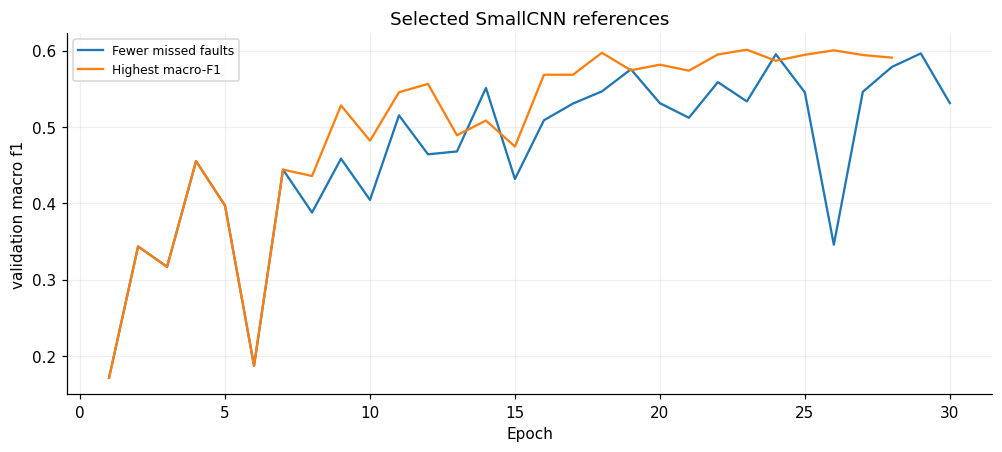

<Axes: title={'center': 'Selected SmallCNN references'}, xlabel='Epoch', ylabel='validation macro f1'>

In [5]:
review = json.loads((ROOT / "results/cnn-error-review-v1.json").read_text())
references = review["models"]
reference_rows = []
for run in references:
    metrics = run["metrics"]
    reference_rows.append({"Role": run["role"], "Run": run["run_id"],
        "Macro-F1": metrics["macro_f1"], "Accuracy": metrics["accuracy"],
        "Balanced accuracy": metrics["balanced_accuracy"], "Missed faults / 1492": metrics["faults_called_normal"],
        "Normal false alarms / 1496": metrics["normal_called_fault"]})
display(pd.DataFrame(reference_rows).set_index("Role").round(4))
all_runs = {run["run_id"]: run for runs in phases.values() for run in runs}
selected_runs = [all_runs[run["run_id"]] for run in references]
assert all(run["summary"]["checkpoint_predictions_verified"] for run in selected_runs)
learning_curves(selected_runs, title="Selected SmallCNN references", labels=[run["role"] for run in references])

## 5. Inspect remaining errors

Each confusion-matrix row sums to 100% of its true class, keeping rare classes visible. Off-diagonal cells are mistakes. The recall table compares how often each true class is recognised.

The example images are previously recorded validation errors selected for illustration. They are not a random estimate of error frequency and do not prove that a label is wrong. Local image previews are optional.

,Fewer missed faults,Highest macro-F1
Cell,0.632,0.643
Cell-Multi,0.409,0.383
Cracking,0.603,0.610
Diode,0.870,0.870
Diode-Multi,0.692,0.615
Hot-Spot,0.405,0.486
Hot-Spot-Multi,0.514,0.595
No-Anomaly,0.840,0.925
Offline-Module,0.634,0.472
Shadowing,0.699,0.538


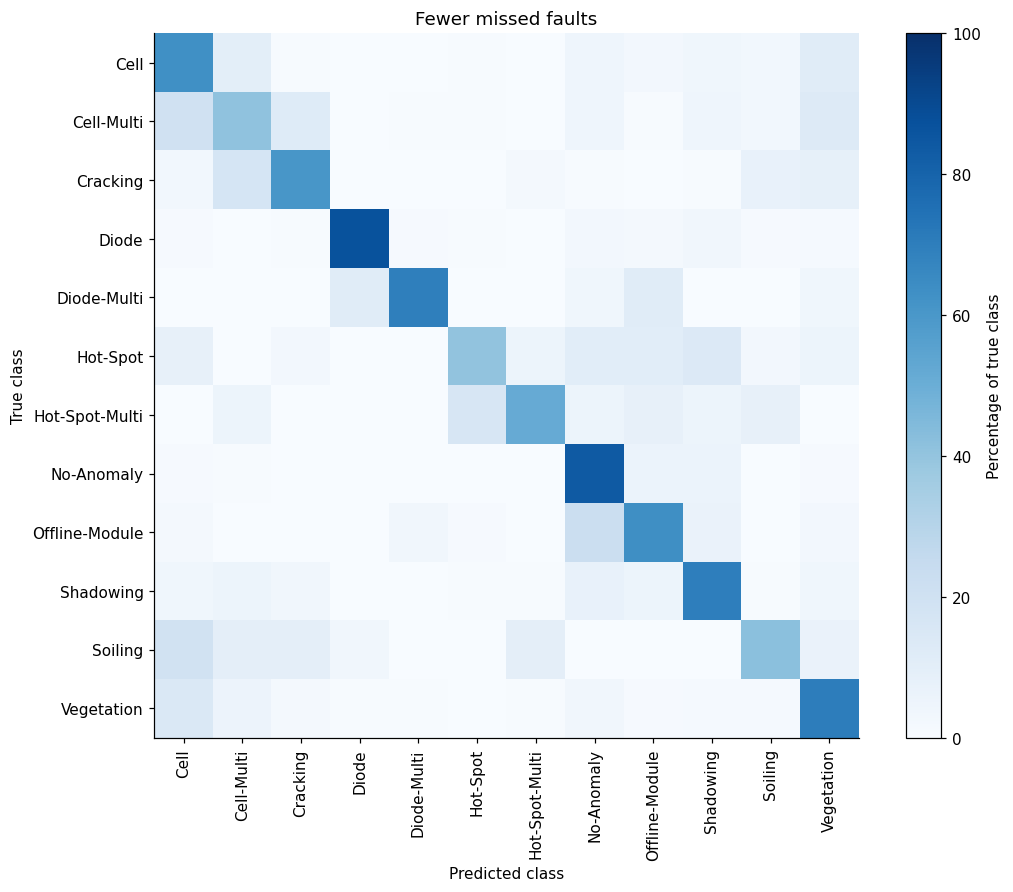

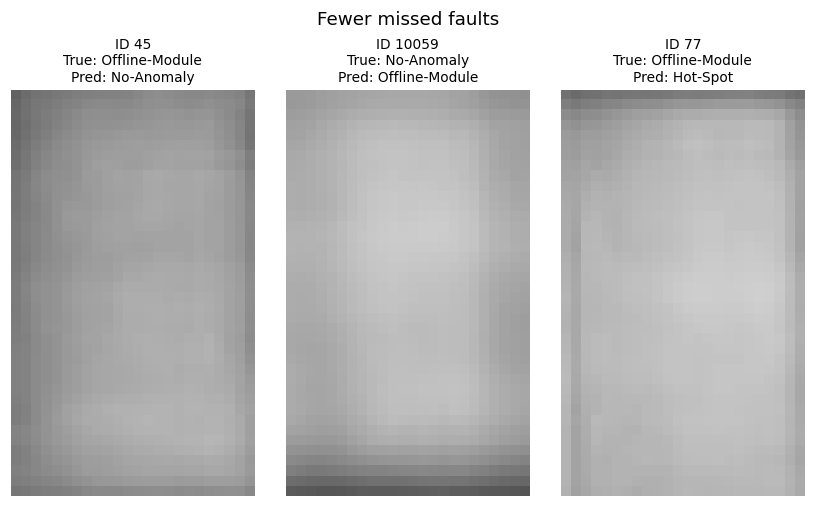

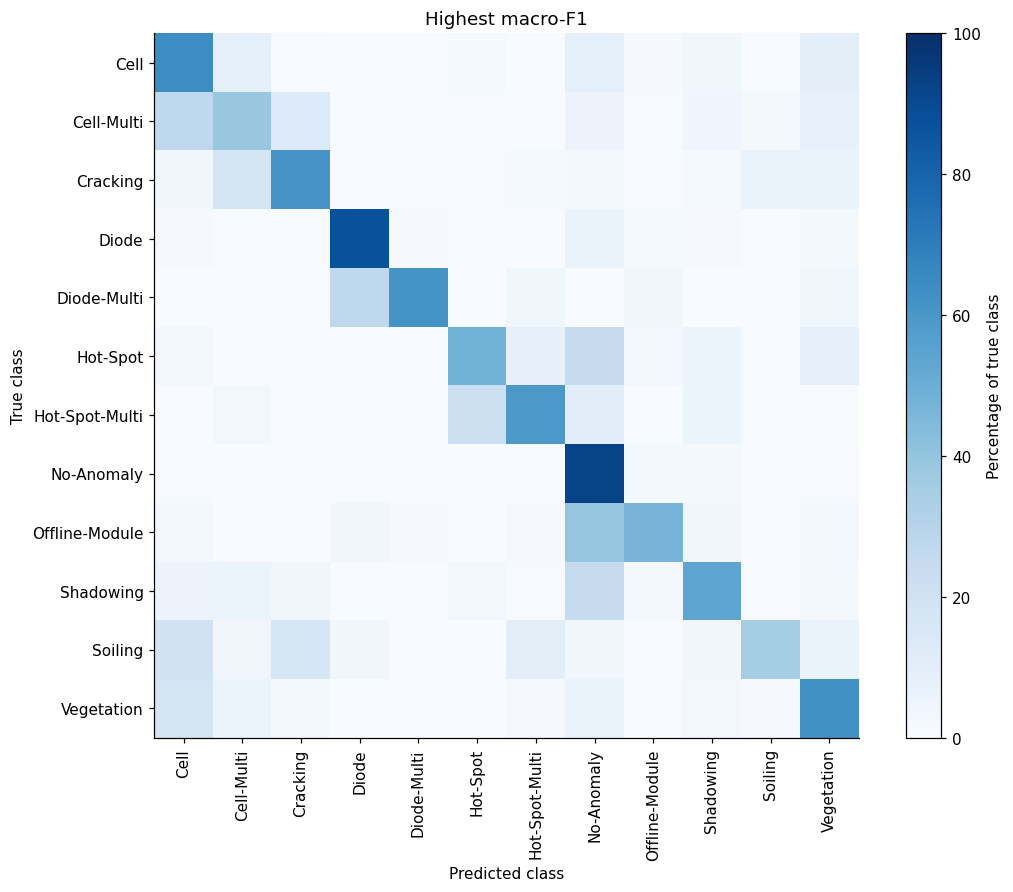

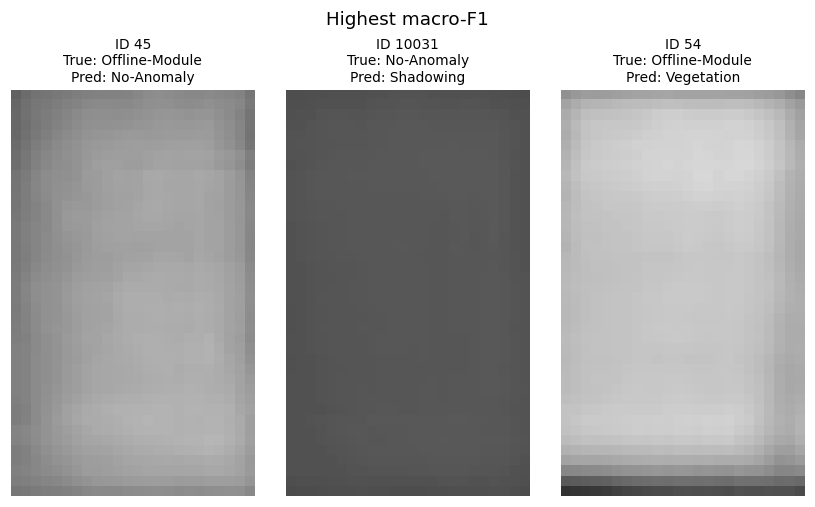

In [6]:
recall = pd.DataFrame({run["role"]: {label: values["recall"]
    for label, values in run["metrics"]["per_class"].items()} for run in references})
display(recall.reindex(CLASS_NAMES).round(3))
for run in references:
    confusion_matrix(run["metrics"], run["role"])
    image_examples(run["examples"], ROOT / "data/raw", run["role"])

## 6. Conclusion and reproduction

SmallCNN learns useful patterns beyond the majority predictor at a small parameter cost. Retain both references for the ResNet comparison: one favours fewer missed faults, the other macro-F1. Neither is a panel-reuse or safety certificate.

The current recipes are:

| Reference | Plan |
|---|---|
| Fewer missed faults | [BatchNorm + depth](../configs/experiment-plan-smallcnn-search-bn-depth.json) |
| Higher macro-F1 | [Gentler scheduling](../configs/experiment-plan-smallcnn-depth-gentle60.json) |

After [data setup](../data/README.md), run a two-batch diagnostic from the repository root:

```bash
PYTHONPATH=src python scripts/train_baseline.py --plan configs/experiment-plan-smallcnn-depth-gentle60.json
```

Full fitting requires `--full` and a new explicit run ID in a copied plan; existing run folders cannot be overwritten. Verify the frozen dataset before fitting. This notebook does not launch training.

Continue to [ResNet experiments](03_resnet18_experiments.ipynb). The [archive index](../archive/README.md) retains the older commands and recipes; full recorded results remain under `results/`.